# `Practical 1`: One Sample T-Test
There are many columns in the titanic dataset. We will deal with `Age` column.

`Note:` We don't know anyone's age, but we just anticipated(Supposed) that the average age of the passengers will be less than 35

So, `Null Hypothesis:-> H0 = mu = 35` <br>
`Alternate Hypothesis-> Ha = mu < 35    (One tailed test)`

- What do we have?
    - mu = 35
    - n = No_of Samples = 25
    - We have samples, so we can find x_bar and s.
    - Population std.dev is not given, so we will conduct `t_test`

In [1]:
import pandas as pd
import numpy as np

np.set_printoptions(suppress=True)

In [2]:
df = pd.read_csv(r"00_Titanic_Dataset.csv")
df = df['Age']

df.dropna(inplace = True)

In [3]:
# Take sample of 35

sample_age = df.sample(25)

sample_age = np.array(sample_age)
sample_age

array([25. , 18. , 57. , 22.5, 14. , 64. , 18. , 29. , 28. , 44. , 50. ,
       19. , 29. , 28. , 33. , 21. , 23. , 19. , 31. , 20. , 52. , 21. ,
       45. , 71. , 27. ])

In [4]:
# Here we took sample of 25 only so, central limit theorem will not be applicable.
# So we will have to check the normality.
# We will use shapiro wilk test

from scipy.stats import shapiro

shapiro_age = shapiro(sample_age)

print(shapiro_age)

# if p_value > sig_level-> The data has normal distribution
# Here p_value is 0.11> 0.05--> So, Normality is satisfied

ShapiroResult(statistic=0.8599768877029419, pvalue=0.002740311436355114)


In [5]:
# Now, main thing starts.
# We will calculate t_value and its area which is p_value
# Till now, we were doing this manually but we have function.
# The function directly returns us p_value and we can then conclude based on it

from scipy.stats import ttest_1samp

# We pass  our sample and population mean
t_statistics, p_value = ttest_1samp(sample_age, 35)

p_value = p_value / 2

print(p_value)

# This returns p_value for two tailed test but as we are performing one tailed, we divide by 2

0.20314414761506394


# Conclusion:
Since significance value is given

`p_value > sig_level means failed to reject Null Hypothesis`

In [6]:
if p_value < 0.05:
    print('Reject the Null hypothesis')
else:
    print("Failed to rejected the Null Hypothesis")

Failed to rejected the Null Hypothesis


In [7]:
# Check the real population mean of Age

df.mean()    # See, it is less than 35. So our conclusion to reject null hypo is correct.

29.881137667304014

# I dont know why is this giving different conclusions each time we rerun the code. Will check it later

# `Practical 2:` Independent 2 Sample T-Test (Unpaired T-Test)

A website owner claims that there's no difference in the average time spent on their website by mobile and desktop users.

To test this claim, we collected the data of 30 mobile users and 30 desktop users.

`The sample statistics are as follows:`

- **Desktop users**
[12, 15, 18, 16, 20, 17, 14, 22, 19, 21, 23, 18, 25, 17, 16, 24, 20, 19, 22, 18, 15, 14, 23, 16, 12, 19, 17, 20, 14]

    - `Sample size (n1)` = 35
    - `Sample mean (x_bar 1)` = 18.2 marks
    - `Sample std.dev (s1)` = 3.5 marks

- **Mobile users:** 
[10, 12, 14, 13, 16, 15, 11, 17, 14, 16, 18, 14, 20, 15, 14, 19, 16, 15, 17, 14, 12, 11, 18, 15, 10, 16, 15, 16, 13, 11]

    - `Sample size (n2)` = 35
    - `Sample mean (x_bar_2)` = 14.5 marks
    - `Sample std.dev (s2)` = 2.7 marks

In [8]:
desktop = np.array([12, 15, 18, 16, 20, 17, 14, 22, 19, 21, 23, 18, 25, 17, 16, 24, 20, 19, 22, 18, 15, 14, 23, 16, 12, 21, 19, 17, 20, 14])
mobile = np.array([10, 12, 14, 13, 16, 15, 11, 17, 14, 16, 18, 14, 20, 15, 14, 19, 16, 15, 17, 14, 12, 11, 18, 15, 10, 16, 15, 16, 13, 11])

print(len(desktop))
print(len(mobile))

x_bar_1 = desktop.mean()
x_bar_2 = mobile.mean()

var_1 = np.var(desktop)
var_2 = np.var(mobile)

n1 = len(desktop)
n2 = len(mobile)

print(x_bar_1)
print(x_bar_2)

print(var_1)
print(var_2)

30
30
18.233333333333334
14.566666666666666
11.712222222222225
6.512222222222222


In [9]:
np.std(desktop)

3.4223124086240615

In [10]:
# Check normality

from scipy.stats import shapiro

# Perform shapiro wilk test for both desktop and mobile

print(f"Shapiro Wilk test for desktop users: {shapiro(desktop)}")
print(f"Shapiro Wilk test for mobile users: {shapiro(mobile)}")

# Here, p_value for both is greater than sig level (0.05)
# So both have almost normal distribution

Shapiro Wilk test for desktop users: ShapiroResult(statistic=0.9783114194869995, pvalue=0.7790969014167786)
Shapiro Wilk test for mobile users: ShapiroResult(statistic=0.9714356064796448, pvalue=0.5791608691215515)


In [11]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Mobile')

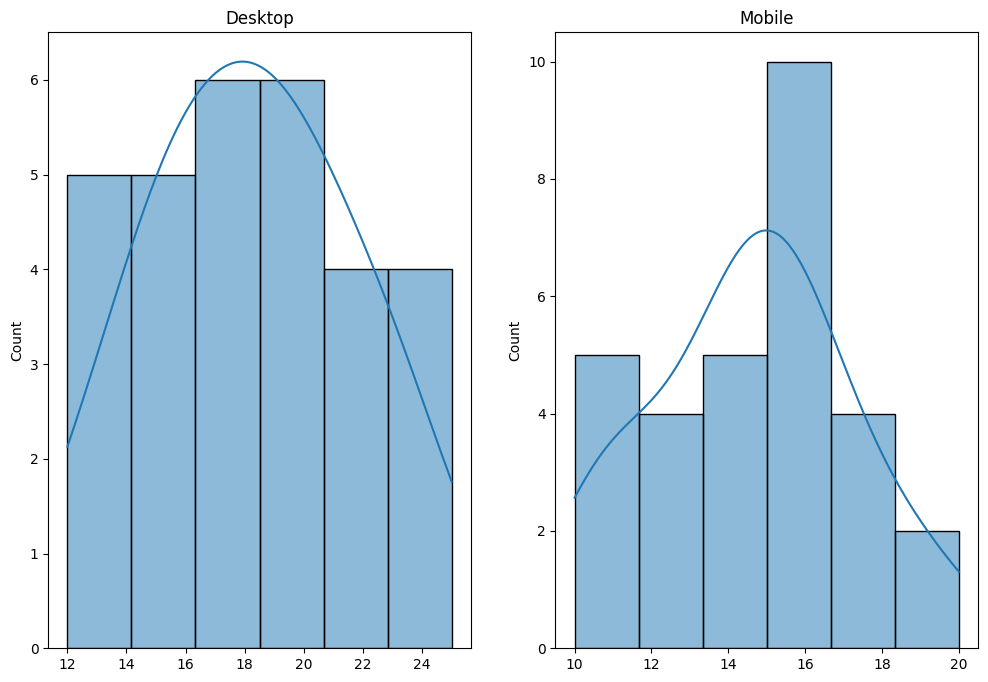

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check normality

fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (12,8))
sns.histplot(desktop, kde = True, ax = axes[0])
axes[0].set_title('Desktop')

sns.histplot(mobile, kde = True, ax = axes[1])
axes[1].set_title('Mobile')

# Both are almost normal


In [13]:
# Check ppopulation variance of both the samples are same

# If the p-value from Levene's test is greater than your chosen significance level (α = 0.05), you can assume equal pop'tion variances
#  If the p-value is less than or equal to the significance level, the assumption of equal variances is not met, 
# and you should consider using Welch's t-test instead of the regular independent two-sample t-test.

from scipy.stats import levene

print(levene(desktop, mobile))

# Here p_value (0.0915) is > sig_level (0.05), so, we can assume that population variance of both the samples is same

LeveneResult(statistic=2.94395488191752, pvalue=0.09153720526741756)


In [14]:
# calculation of t_cal

t_cal = ((x_bar_1 - x_bar_2)) / (np.sqrt((var_1/n1) + (var_2/n2)))
print(t_cal)

4.704407229871296


In [15]:
# Calculate area for t_cal. This returns area from the left. As this is two tailed test, we will multiply by 2
from scipy.stats import t

df = n1+n2-2
cdf = t.cdf(-5.25, df)
print(cdf*2)

print(f"{cdf*2: .10f}")


2.2563697469332243e-06
 0.0000022564


In [16]:
if cdf*2 < 0.05:
    print("Reject the null hypothesis")
else:
    print("Failed to reject the null hypothesis")


Reject the null hypothesis


# Conclusion:
- We reject our Null Hypothesis here. So it means the hypothesis we made, i.e desktop and mobile users both have same average screen time is not correct.
- Remember, we have proved that the average screen time is not equal.
- We don't know if Mean(Desktop)>Mean(Mobile)

In [17]:
print(np.mean(desktop))
print(np.mean(mobile))

# See, means are different


18.233333333333334
14.566666666666666


# `Practical 3:` Titanic Dataset--> 2 Sample T-Test

Our hypothesis is, average age of male is higher than the average age of females

- `Null Hypo` = Avg(Male) = Avg(Female)
- `Alternate Hypo` = Avg(Male) > Avg(Female) **(One tailed test)**

In [18]:
titanic = pd.read_csv(r"00_Titanic_Dataset.csv")
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [19]:
# Extract males' and females' data

pop_male = titanic[titanic['Sex'] == 'male'] ['Age'].dropna()
pop_female = titanic[titanic['Sex'] == 'female'] ['Age'].dropna()

pop_male.head()

0     22.0
4     35.0
6     54.0
7      2.0
12    20.0
Name: Age, dtype: float64

In [20]:
# Take sample of 25
sample_male = pop_male.sample(35)
sample_female = pop_female.sample(35)

Text(0.5, 1.0, 'Age(Female)')

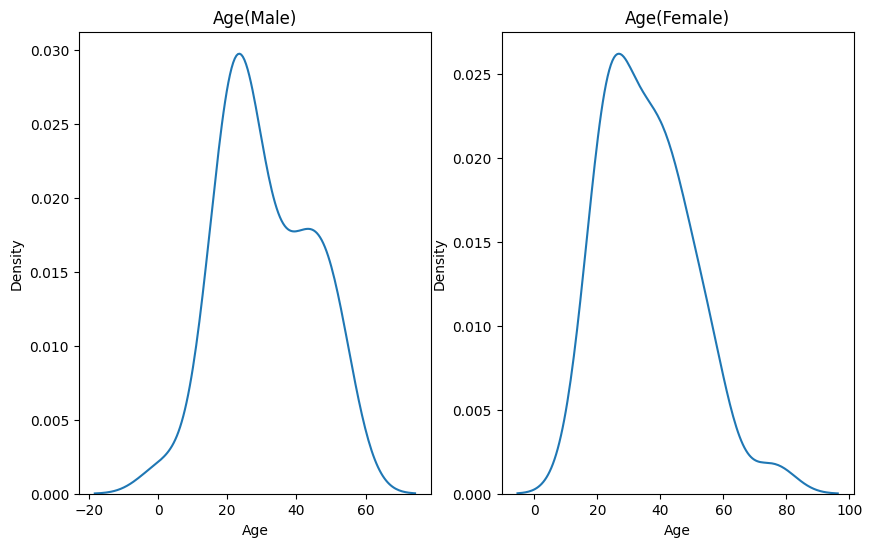

In [21]:
# Check normality using graph/ shapiro test
# shapiro test is the best

fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (10,6))
sns.kdeplot(sample_male,ax = axes[0])
axes[0].set_title('Age(Male)')

sns.kdeplot(sample_female, ax = axes[1])
axes[1].set_title('Age(Female)')

# Both are almost normal.
# Now check if variance of both are same

In [22]:
# shapiro test to check normality

t_statistics_female, p_value_female = shapiro(sample_female)
t_statistics_male, p_value_male = shapiro(sample_male)

print(f"""P_value(Female): {p_value_female}
P_value(Male): {p_value_male}""")

# See, p_value of both male and female > Sig_level(5%).
# So both have normal distribution which we saw in above graph as well

P_value(Female): 0.0736585184931755
P_value(Male): 0.12493159621953964


In [23]:
# Check ppopulation variance of both the samples are same

# If the p-value from Levene's test is greater than your chosen significance level (α = 0.05), you can assume equal pop'tion variances
#  If the p-value is less than or equal to the significance level, the assumption of equal variances is not met, 
# and you should consider using Welch's t-test instead of the regular independent two-sample t-test.

p_value = levene(pop_male, pop_female)
p_value

# Here p_value>Sig_level so Variance test also passed.
# Now we can calculate t_cal

LeveneResult(statistic=0.749517171340845, pvalue=0.38682804247347446)

In [24]:
# Calculate t_cal

from scipy.stats import ttest_ind

t_statistics, p_value = ttest_ind(sample_male, sample_female)
p_value = p_value/2
print(f"""t_statistics: {t_statistics}
p_value: {p_value}""")

# Since it is a one tailed test, we divide p_value by 2

t_statistics: -1.529753883205288
p_value: 0.06535829651299427


In [25]:
alpha = 5/100

if p_value<=alpha:
    print("Reject the Null Hypothesis")
else:
    print("Failed to reject the Null Hypothesis")

Failed to reject the Null Hypothesis


# Conclusion:

- Here, `p_value>alpha (0.05)`, so we `failed to reject the Null Hypothesis`
- So, our alternate hypothesis is proved to be correct
- This means mean age of male != mean age of female (Null Hypo)
- Mean age of male > mean age of female (Alternate Hypo)


In [26]:
# Check if our hypo is truly wrong

print(f"""Mean Age of Male: {np.mean(pop_male)}
Mean Age of Female: {np.mean(pop_female)}""")

Mean Age of Male: 30.58522796352584
Mean Age of Female: 28.68708762886598


# Now understand this very carefully.

- Whenever we reject null hypothesis, it means alternate hypothesis is correct.
- But if we fail to reject the null hypothesis, it doesn't mean that Null Hypothesis is correct.
- This simply means that right now we don't have enough evidence to reject the null hypothesis.
- May we have more samples, we could have rejected the null hypothesis
- `We can take more samples and see the result`

# Paired T-Test/ Dependent T-Test

A fitness center is evaluating the effectiveness of new weight loss program. They enrolled 15 participants in this new program and measured their weight before and after the program.

The goal is to test whether the new weight loss program significantly reduces the weight of the participants.

In [27]:
before = np.array([80, 92, 75, 68, 85, 78, 73, 90, 70, 88, 76, 84, 82, 77, 91])
after = np.array([78, 93, 81, 67, 88, 76, 74, 91, 69, 88, 77, 81, 80, 79, 88])

difference = before-after

ShapiroResult(statistic=0.9220570921897888, pvalue=0.20704729855060577)

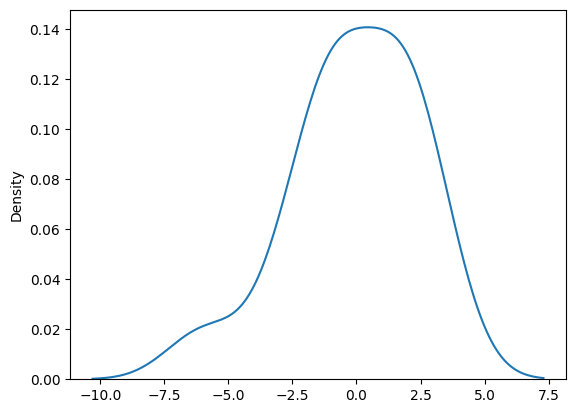

In [28]:
# Check normality of the difference

sns.kdeplot(difference)

# Shapiro-Wilk test to check the normality
shapiro(difference)

# We can see the graph and it is almost normal distribution
# Also from shapiro test, p_value>sig_level. So it is normal

In [29]:
# Calculate t_cal

mean_difference = np.mean(difference)
std_difference = np.std(difference)
n = len(difference)
print(mean_difference, ',', std_difference)

tcal = (mean_difference)/ (std_difference/np.sqrt(n))
tcal

-0.06666666666666667 , 2.379542439676633


-0.10850778933039285

In [38]:
alpha = 0.05
df = n-1
p_value = t.cdf(tcal, df)
p_value

0.45756637096100794

In [39]:
if p_value<alpha:
    print("Reject the Null Hypo")
else:
    print("Failed to reject the Null Hypo")

Failed to reject the Null Hypo


# Conclusion:
- Here we failed to reject the null hypothesis.
- Means right now we don't have enough evidence to reject the null hypothesis
- Let's see if mean(before) = mean(after)

In [37]:
print(before.mean())
print(f"{after.mean():.2f}")



80.6
80.67
